# Training

Policy gradient on the Zamboni task (`pg1`, Algorithm 1): GPOMDP with its baseline and Adam, at m = 75 kg and C = 0.5. Two trainings with the same budget of 100 000 episodes: the first guess (n = 100 episodes per iteration, K = 1000 iterations, lr = 0.001) and the values chosen by the tuning on validation episodes (n = 50, K = 2000, lr = 0.01, the defaults of `Config`, see `experiments.ipynb`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from zamboni.controllers import PDController
from zamboni.env import RINK_HALF_X, RINK_HALF_Y, TARGET_WINDOW, ZamboniEnv
from zamboni.policy import LinearGaussianPolicy
from zamboni.training import Config, evaluate, train

configs = {
    "first guess": Config(batch_size=100, iterations=1000, lr=0.001),
    "tuned": Config(),
}
runs = {name: train(cfg) for name, cfg in configs.items()}
cfg = configs["tuned"]  # m and C are the same for both

## Learning curves

The return is the batch average at each iteration, an estimate of J(θ_k) for the policy with its noise. The horizontal axis counts the episodes played, so the two trainings use the same budget. σ is the noise of the policy, learned with the other parameters.

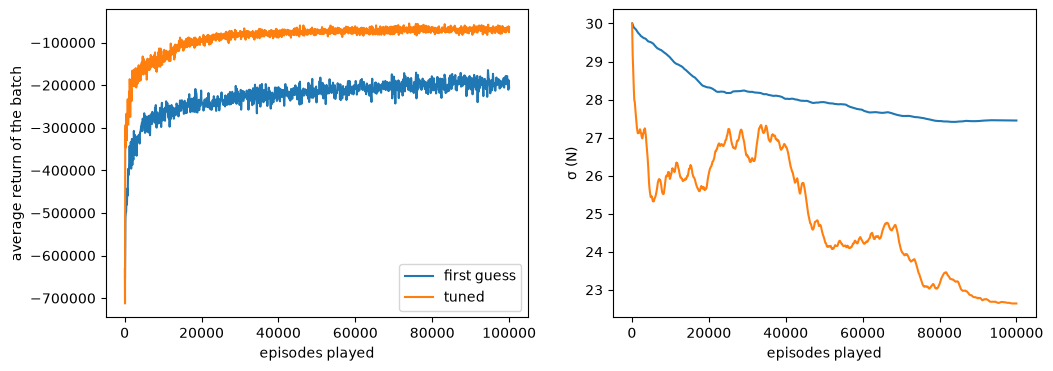

In [2]:
fig, (ax_return, ax_sigma) = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, history) in runs.items():
    episodes = configs[name].batch_size * np.arange(1, configs[name].iterations + 1)
    ax_return.plot(episodes, history["return"], label=name)
    ax_sigma.plot(episodes, history["sigma"], label=name)
ax_return.set_xlabel("episodes played")
ax_return.set_ylabel("average return of the batch")
ax_sigma.set_xlabel("episodes played")
ax_sigma.set_ylabel("σ (N)")
ax_return.legend()
plt.show()

## Against hand-designed controllers

Two PD controllers drive the robot on the same test episodes as the learned policies: the critically damped PD with kp = 10 N/m, and the PD with the gains of the LQR. The dashed lines are the two PDs without noise, while the curves are the learned policies with their noise, which costs extra: the fair comparison is the table above the plot.

PG first guess       return   -179114, targets reached 0.23 of 3
PG tuned             return    -65858, targets reached 2.48 of 3
critically damped PD return    -87155, targets reached 3.00 of 3
LQR PD               return    -81592, targets reached 3.00 of 3


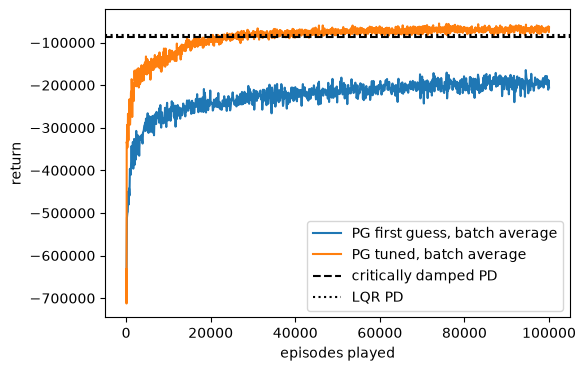

In [3]:
controllers = {
    "critically damped PD": PDController.critically_damped(cfg.mass),
    "LQR PD": PDController.lqr(cfg.mass, cfg.energy_coeff),
}
acts = {f"PG {name}": policy.act for name, (policy, _) in runs.items()}
acts |= {name: controller.act for name, controller in controllers.items()}
results = {name: evaluate(act, cfg.mass, cfg.energy_coeff) for name, act in acts.items()}
for name, r in results.items():
    print(f"{name:20} return {r['return']:9.0f}, targets reached {r['targets_reached']:.2f} of 3")

plt.figure(figsize=(6, 4))
for name, (_, history) in runs.items():
    episodes = configs[name].batch_size * np.arange(1, configs[name].iterations + 1)
    plt.plot(episodes, history["return"], label=f"PG {name}, batch average")
for name, style in [("critically damped PD", "--"), ("LQR PD", ":")]:
    plt.axhline(results[name]["return"], color="black", linestyle=style, label=name)
plt.xlabel("episodes played")
plt.ylabel("return")
plt.legend()
plt.show()

## The policy along the training

The path of the robot in the first 20 s window (one target), driven by the mean command without noise, at three points of the tuned training. At iteration 0 the weights are zero, so the mean command is zero and the robot does not move.

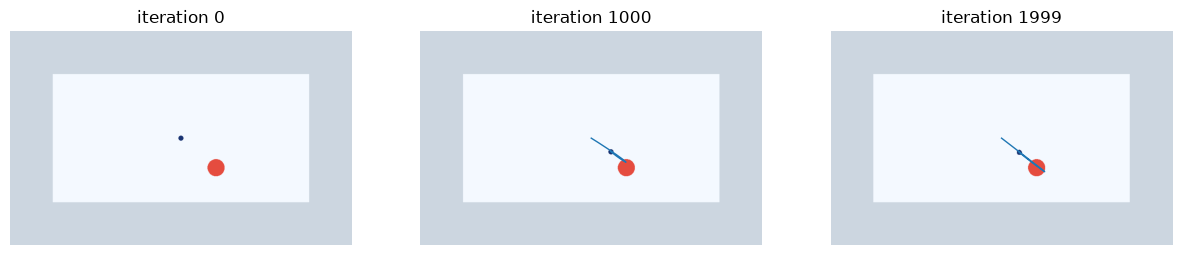

In [4]:
def first_window(theta, seed=0):
    replay = LinearGaussianPolicy()
    replay.theta = theta
    env = ZamboniEnv(render_mode="rgb_array")
    obs, _ = env.reset(seed=seed)
    path = [obs[:2]]
    for _ in range(TARGET_WINDOW - 1):  # stop before the target changes
        obs, *_ = env.step(replay.act(obs))
        path.append(obs[:2])
    return env.render(), np.array(path)


_, history = runs["tuned"]
view = [-RINK_HALF_X - 10, RINK_HALF_X + 10, -RINK_HALF_Y - 10, RINK_HALF_Y + 10]  # as render()
iterations = [0, cfg.iterations // 2, cfg.iterations - 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, k in zip(axes, iterations, strict=True):
    image, path = first_window(history["theta"][k])
    ax.imshow(image, extent=view)
    ax.plot(path[:, 0], path[:, 1], color="tab:blue", linewidth=1)
    ax.set_title(f"iteration {k}")
    ax.axis("off")
plt.show()